In [4]:
!git clone -q https://github.com/tangsanli5201/DeepPCB.git


fatal: destination path 'DeepPCB' already exists and is not an empty directory.


In [5]:
import os
import cv2
import matplotlib.pyplot as plt


In [6]:
# Find PCB test images
root = "DeepPCB/PCBData"

test_images = []

for folder, dirs, files in os.walk(root):
    for file in files:
        if "_test.jpg" in file:
            test_images.append(
                os.path.join(folder, file)
            )

print("Test images found:", len(test_images))



Test images found: 1500


Template: (640, 640)
Test: (640, 640)


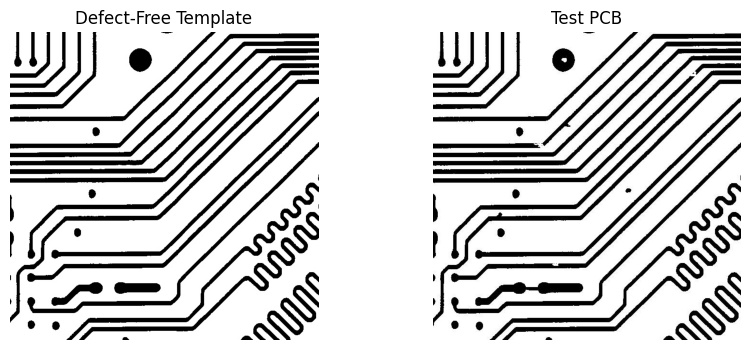

In [7]:
# Corresponding template image
template_path = test_path.replace(
    "_test.jpg",
    "_temp.jpg"
)

template = cv2.imread(
    template_path,
    cv2.IMREAD_GRAYSCALE
)

test = cv2.imread(
    test_path,
    cv2.IMREAD_GRAYSCALE
)

print("Template:", template.shape)
print("Test:", test.shape)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(template, cmap="gray")
plt.title("Defect-Free Template")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(test, cmap="gray")
plt.title("Test PCB")
plt.axis("off")

plt.show()

In [8]:
# Calculate absolute difference
difference = cv2.absdiff(
    template,
    test
)

# Threshold the difference
_, defect_mask = cv2.threshold(
    difference,
    30,
    255,
    cv2.THRESH_BINARY
)

# Remove small noise
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (5, 5)
)

defect_mask = cv2.morphologyEx(
    defect_mask,
    cv2.MORPH_OPEN,
    kernel
)

defect_mask = cv2.morphologyEx(
    defect_mask,
    cv2.MORPH_CLOSE,
    kernel
)


In [9]:
# Find defect regions
contours, _ = cv2.findContours(
    defect_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

result = cv2.cvtColor(
    test,
    cv2.COLOR_GRAY2BGR
)

for contour in contours:

    area = cv2.contourArea(contour)

    if area > 10:

        x, y, w, h = cv2.boundingRect(
            contour
        )

        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 0, 255),
            2
        )

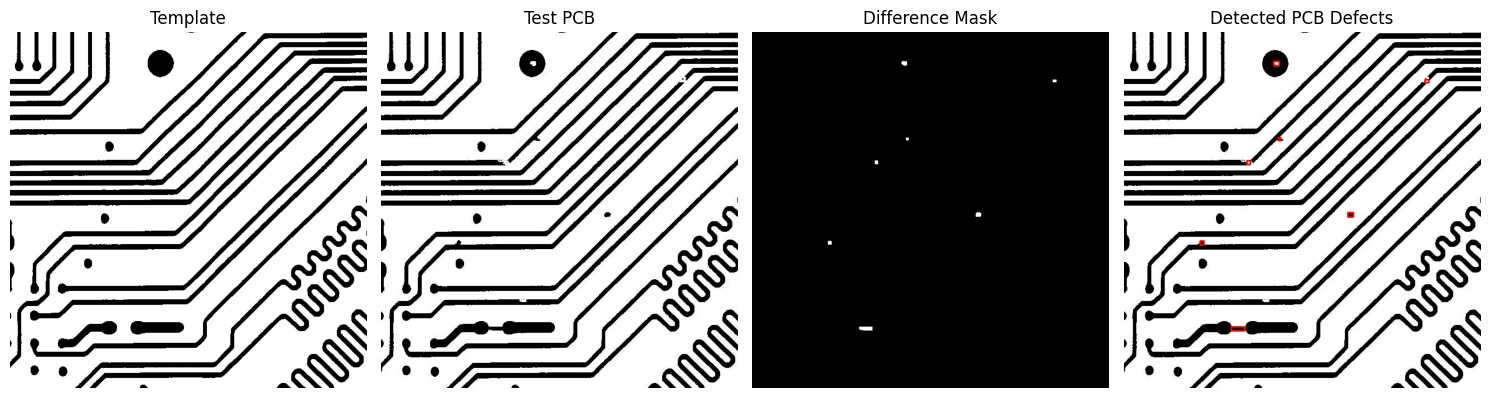

In [10]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 4, 1)
plt.imshow(template, cmap="gray")
plt.title("Template")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(test, cmap="gray")
plt.title("Test PCB")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(defect_mask, cmap="gray")
plt.title("Difference Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(
    cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
)
plt.title("Detected PCB Defects")
plt.axis("off")

plt.tight_layout()
plt.show()